## Energy calculation along a route
In this notebook we set up a basic simulation where one vessel moves over a 1D network path consisting of three edges each 100 km long. The middle section has a shallower depth than the other sections. The calculations show the estimated energy consumption along the route.

In [13]:
# package(s) used for creating and geo-locating the graph
import networkx as nx
from pyproj import Geod
from shapely.geometry import Point

# package(s) related to the simulation (creating the vessel, running the simulation)
import datetime
import simpy
import opentnsim

# OpenTNSim mixins and utils
from opentnsim.core import Identifiable, Movable, VesselProperties, ExtraMetadata
from opentnsim.core.logutils import logbook2eventtable
from opentnsim.core.utils import create_object, inspect_object
from opentnsim.energy import ConsumesEnergy
from opentnsim.energy.logutils import (
    add_energy_attributes_to_eventtable,
    add_fuel_attributes_to_event_table,
)
from opentnsim.graph.visualizations import plot_graph

# package(s) needed for inspecting the output
import pandas as pd

# package(s) needed for plotting
import plotly.graph_objects as go
from plotly.subplots import make_subplots

print("This notebook is executed with OpenTNSim version {}".format(opentnsim.__version__))

This notebook is executed with OpenTNSim version 2.3.2a2.dev3+g514a752b4.d20260603


#### 0. Create environment
We create the environment

In [2]:
# start simpy environment
simulation_start = datetime.datetime(2024, 1, 1, 0, 0, 0)
env = simpy.Environment(initial_time=simulation_start.timestamp())
env.epoch = simulation_start

#### 1. Create graph
Next we create our graph. This case we create a single edge of 100 km exactly.

In [3]:
# initialize geodetic calculator with WGS84 ellipsoid
geod = Geod(ellps="WGS84")

# starting point (longitude, latitude)
lon0, lat0 = 0, 0

# compute the other point 100 km East from Point 0
lon1, lat1, _ = geod.fwd(lon0, lat0, 90, 100000) # East from Point 0
lon2, lat2, _ = geod.fwd(lon1, lat1, 90, 100000) # East from Point 1
lon3, lat3, _ = geod.fwd(lon2, lat2, 90, 100000) # East from Point 2

# define nodes with their geographic coordinates
coords = {
    "0": (lon0, lat0),
    "1": (lon1, lat1),
    "2": (lon2, lat2),
    "3": (lon3, lat3),
}

In [4]:
# create a directed graph
FG = nx.DiGraph()

# add nodes
for name, coord in coords.items():
    FG.add_node(name, geometry=Point(coord[0], coord[1]))

In [5]:
# create list of edges
edges = [
    ("0", "1"), ("1", "0"),
    ("1", "2"), ("2", "1"),
    ("2", "3"), ("3", "2"),
] # bi-directional edge

# add edges
for edge in edges:
    FG.add_edge(edge[0], edge[1], weight=1)

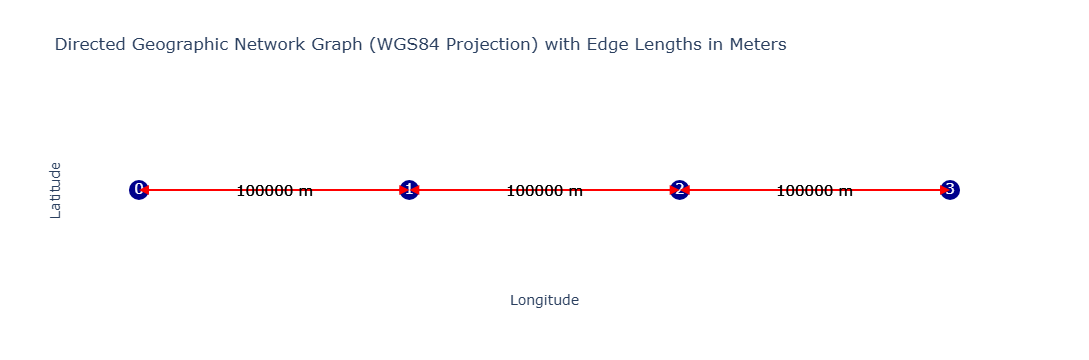

In [6]:
plot_graph(FG)

In [7]:
FG.edges['0', '1']['GeneralDepth'] = 6
FG.edges['1', '0']['GeneralDepth'] = 6
FG.edges['1', '2']['GeneralDepth'] = 4.5
FG.edges['2', '1']['GeneralDepth'] = 4.5
FG.edges['2', '3']['GeneralDepth'] = 6
FG.edges['3', '2']['GeneralDepth'] = 6

In [8]:
env.graph = FG

#### 2. Create vessel

In [9]:
# make your preferred Vessel class out of available mixins.
Vessel = create_object(
    "Vessel", 
    (
        ConsumesEnergy,
        Identifiable,                       # allows to give the object a name and a random ID,
        Movable,                            # allows the object to move, with a fixed speed, while logging this activity
        VesselProperties,
        ExtraMetadata,
    ), 
)

In [10]:
def mission(env, vessel):
    """Method that defines the mission of the vessel. 
    
    In this case: 
        keep moving along the path until its end point is reached
    """
    
    while True:
        yield from vessel.move()
        
        if vessel.geometry == nx.get_node_attributes(env.graph, "geometry")[vessel.route[-1]]:
            break

In [11]:
# create vessel from a dict 
route = nx.dijkstra_path(env.graph, "0", "3")
data_vessel = {
    "env": env,
    "name": 'Vessel',           # you can give the vessel an arbitratry name
    "type": 'Va/M9 - Verl. Groot Rijnschip', # This indicates the vessel class. This info is mainly informative.
    "L": 110,                   # m
    "B": 11.4,                  # m
    "T": 3.5,                   # m
    "v": 3,                     # m/s If None: this value is calculated based on P_tot_given
    "safety_margin": 0.2,       # for tanker vessel with sandy bed the safety margin is recommended as 0.2 m 
    "h_squat": False,            # if the ship should squat while moving, set to True, otherwise set to False
    "P_installed": 1750.0,      # kW
    "P_tot_given": None,        # kW If None: this value is calculated value based on speed
    "bulbous_bow": False,       # if a vessel has no bulbous_bow, set to False; otherwise set to True.
    "karpov_correction": False, # if False, don't apply the karpov correction, if True, apply the karpov correction
    "P_hotel_perc": 0.05,       # 0: all power goes to propulsion
    "P_hotel": None,            # None: calculate P_hotel from percentage
    "x": 2,                     # number of propellers
    "L_w": 3.0 ,
    "C_B": 0.85,                # block coefficient 
    "C_year": 1990,             # engine build year
    "arrival_time": datetime.datetime(2024, 1, 1, 0, 0, 0),
    "geometry": env.graph.nodes[route[0]]['geometry'],
    "route": route,             # the route to sail
}  # 

# create an instance of the Vessel class using the input dict data_vessel
vessel = Vessel(**data_vessel)

# start the simulation
env.process(mission(env, vessel));

In [14]:
inspect_object(Vessel)

,parameter,class,status
0,L_w,ConsumesEnergy,required
1,P_installed,ConsumesEnergy,required
2,name,Identifiable,required
3,geometry,Locatable,required
4,v,Movable,required
5,route,Routable,required
6,env,SimpyObject,required
7,B,VesselProperties,required
8,L,VesselProperties,required
9,T,VesselProperties,required


#### 3. Run simulation

In [ ]:
env.run()

#### 4. Inspect output
We can now inspect  the simulation output by inspecting the _vessel.logbook_. Note that the _Log_ mix-in was included when we added _Movable_. The _vessel.logbook_ keeps track of the moving activities of the vessel. For each discrete event OpenTNSim logs an event message, the start/stop time and the location. The _vessel.logbook_ is of type dict. For convenient inspection it can be loaded into a Pandas dataframe. 

In [ ]:
# load the logbook data into a dataframe
df = pd.DataFrame.from_dict(vessel.logbook)

display(df)

In [ ]:
df_eventtable = logbook2eventtable([vessel])
df_eventtable

In [ ]:
# add energy attributes to the minimum event table
df_eventtable_energy = add_energy_attributes_to_eventtable(df_eventtable, [vessel])        

pd.set_option('display.max_columns', None)
df_eventtable_energy

In [ ]:
# add fuel attributes to the minimum event table with energy attributes
df_eventtable_energy_fuel = add_fuel_attributes_to_event_table(df_eventtable_energy, [vessel])

pd.set_option('display.max_columns', None)
df_eventtable_energy_fuel

We can plot the parameters from the eventtable:

In [ ]:
# Calculate durations in minutes
durations = [
    (row['stop time'] - row['start time']).total_seconds() / 60
    for _, row in df_eventtable_energy_fuel.iterrows()
]

# Create 2x2 subplot figure
fig = make_subplots(rows=2, cols=2, subplot_titles=[
    'Average Speed per Section [m/s]',
    'Average Power Given per Section [kW]',
    'Total Section Transit Time [mins]',
    'Total Section Transit Energy [kWh]'
])

# Add bar charts to subplots
fig.add_trace(go.Bar(x=df.index, y=df_eventtable_energy_fuel['speed over ground (m/s)'], name='Speed [m/s]'), row=1, col=1)
fig.add_trace(go.Bar(x=df.index, y=df_eventtable_energy_fuel['P_given (kW)'], name='Power Given [kW]'), row=1, col=2)
fig.add_trace(go.Bar(x=df.index, y=df_eventtable_energy_fuel['duration (s)'], name='Transit Time [mins]'), row=2, col=1)
fig.add_trace(go.Bar(x=df.index, y=df_eventtable_energy_fuel['total_energy (kWh)'], name='Energy [kWh]'), row=2, col=2)

# Update layout
fig.update_layout(
    height=800,
    width=1000,
    title_text='Section Analysis',
    plot_bgcolor='white'
)

fig.show()

We observe that the vessel had to use more power in the shallow section of the waterway to maintain its cruising speed of 3.0 m/s.